<a href="https://colab.research.google.com/github/cristobalcresposandoval-lang/CSN/blob/main/core_simulacion_de_examen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Datos originales:
   user_id  app_version platform  session_duration  number_of_sessions  \
0        1          1.2  Android               109                  11   
1        2          1.3  Android               116                  17   
2        3          1.0  Android                94                  13   
3        4          1.2      iOS                47                   1   
4        5          1.2      iOS                99                   2   

  country  user_feedback  
0  France              1  
1      UK              2  
2  France              5  
3  Canada              4  
4  Canada              3  
Valores faltantes:
user_id               0
app_version           0
platform              0
session_duration      0
number_of_sessions    0
country               0
user_feedback         0
dtype: int64
Datos después de la limpieza:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 7 columns):
 #   Column              Non-Null Count  

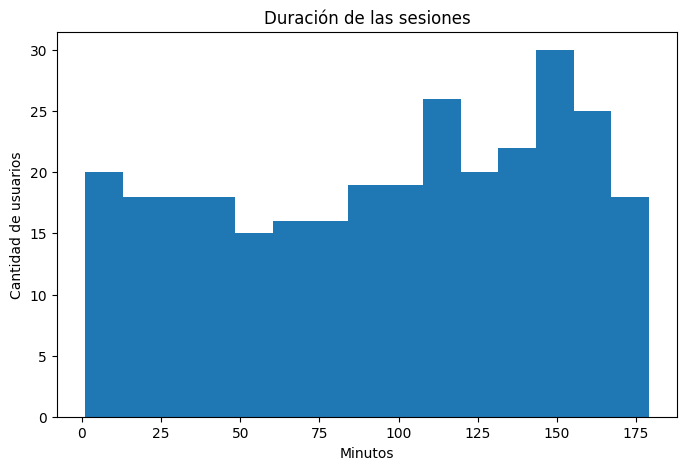

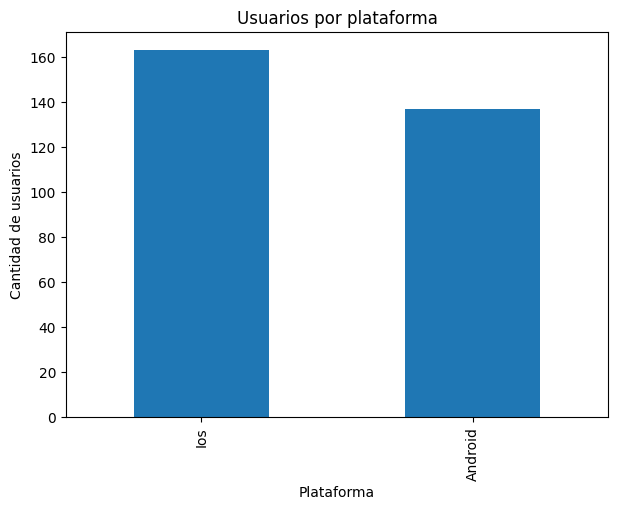

<Figure size 800x500 with 0 Axes>

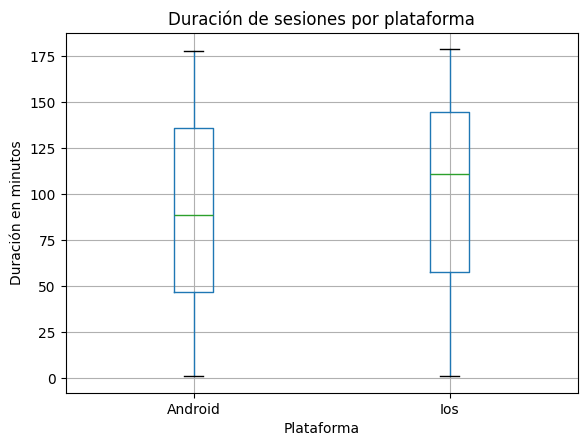

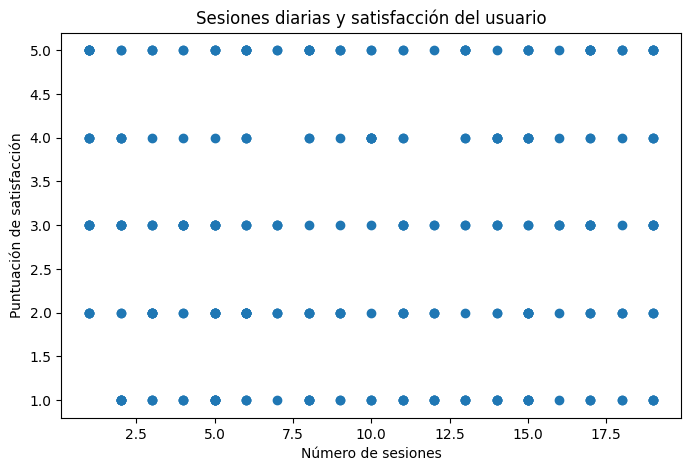

Análisis de datos finalizado correctamente.


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =====================================
# 1. GENERAR LOS DATOS
# =====================================

np.random.seed(42)

user_id = range(1, 301)
app_version = np.random.choice(['1.0', '1.1', '1.2', '1.3'], 300)
platform = np.random.choice(['Android', 'iOS'], 300)
session_duration = np.random.randint(1, 180, 300)
number_of_sessions = np.random.randint(1, 20, 300)
country = np.random.choice(['USA', 'Canada', 'Mexico', 'UK',
                            'Germany', 'France', 'Spain', 'Italy'], 300)
user_feedback = np.random.randint(1, 6, 300)

data = pd.DataFrame({
    'user_id': user_id,
    'app_version': app_version,
    'platform': platform,
    'session_duration': session_duration,
    'number_of_sessions': number_of_sessions,
    'country': country,
    'user_feedback': user_feedback
})

data.to_csv('user_app_data.csv', index=False)

# =====================================
# 2. CARGAR LOS DATOS
# =====================================

df = pd.read_csv('user_app_data.csv')

print("Datos originales:")
print(df.head())

# =====================================
# 3. LIMPIEZA DE DATOS
# =====================================

# Eliminar datos duplicados
df = df.drop_duplicates()

# Eliminar identificaciones repetidas
df = df.drop_duplicates(subset='user_id')

# Revisar valores faltantes
print("Valores faltantes:")
print(df.isnull().sum())

# Completar datos faltantes
# En números usamos la mediana y en categorías la moda.
for col in ['session_duration', 'number_of_sessions',
            'user_feedback']:
    df[col] = df[col].fillna(df[col].median())

for col in ['app_version', 'platform', 'country']:
    df[col] = df[col].fillna(df[col].mode()[0])

# Corregir tipos de datos
df['user_id'] = df['user_id'].astype(int)
df['session_duration'] = df['session_duration'].astype(int)
df['number_of_sessions'] = df['number_of_sessions'].astype(int)
df['user_feedback'] = df['user_feedback'].astype(int)

# Normalizar categorías
df['platform'] = df['platform'].str.strip().str.capitalize()
df['country'] = df['country'].str.strip().str.capitalize()
df['app_version'] = df['app_version'].astype(str).str.strip()

# Detectar valores inusuales
df = df[
    (df['session_duration'] > 0) &
    (df['session_duration'] <= 10080) &
    (df['number_of_sessions'] > 0) &
    (df['user_feedback'].between(1, 5))
]

print("Datos después de la limpieza:")
print(df.info())

# Guardar datos limpios
df.to_csv('user_app_data_limpios.csv', index=False)

# =====================================
# 4. EXPLORACIÓN UNIVARIANTE
# =====================================

# Gráfico 1: Histograma de duración de sesiones
plt.figure(figsize=(8, 5))
plt.hist(df['session_duration'], bins=15)
plt.title('Duración de las sesiones')
plt.xlabel('Minutos')
plt.ylabel('Cantidad de usuarios')
plt.show()

# Interpretación:
# El histograma permite observar cuánto duran las sesiones.
# Muestra en qué intervalos se concentran más usuarios.

# Gráfico 2: Gráfico de barras de plataformas
plt.figure(figsize=(7, 5))
df['platform'].value_counts().plot(kind='bar')
plt.title('Usuarios por plataforma')
plt.xlabel('Plataforma')
plt.ylabel('Cantidad de usuarios')
plt.show()

# Interpretación:
# Este gráfico permite comparar la cantidad de usuarios
# que utilizan Android y iOS.

# =====================================
# 5. EXPLORACIÓN MULTIVARIANTE
# =====================================

# Gráfico 3: Duración de sesión según plataforma
plt.figure(figsize=(8, 5))
df.boxplot(column='session_duration', by='platform')
plt.title('Duración de sesiones por plataforma')
plt.suptitle('')
plt.xlabel('Plataforma')
plt.ylabel('Duración en minutos')
plt.show()

# Interpretación:
# Permite comparar la duración de las sesiones entre Android
# e iOS e identificar diferencias y valores extremos.

# Gráfico 4: Relación entre sesiones y comentarios
plt.figure(figsize=(8, 5))
plt.scatter(df['number_of_sessions'], df['user_feedback'])
plt.title('Sesiones diarias y satisfacción del usuario')
plt.xlabel('Número de sesiones')
plt.ylabel('Puntuación de satisfacción')
plt.show()

# Interpretación:
# Permite observar si existe alguna relación entre la cantidad
# de sesiones diarias y la satisfacción de los usuarios.

print("Análisis de datos finalizado correctamente.")
